# Food Delivery Customer Spending Prediction – Linear Regression

Predict the **yearly amount (INR) a customer spends** on a food-delivery platform from their behaviour: order frequency, time on the app, time on the website and length of membership.

Two models are built and compared:
- **Simple Linear Regression** – one feature
- **Multiple Linear Regression** – all four features

> The dataset (`Food Delivery Customers.csv`) is synthetic and was generated with `generate_dataset.py` (seed 7).

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
BLUE, ORANGE = "#2a6fdb", "#e8833a"
print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the Dataset

In [2]:
df = pd.read_csv("Food Delivery Customers.csv")
df.head()

,Email,City,Avatar,Avg. Orders per Month,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,customer001@example.com,Delhi,Indigo,6.00,13.43,31.44,2.28,81358.45
1,customer002@example.com,Pune,Teal,6.45,10.99,31.57,5.14,99622.02
2,customer003@example.com,Mumbai,Olive,5.59,12.05,28.32,4.01,89096.06
3,customer004@example.com,Lucknow,Olive,4.66,16.77,38.08,5.29,103710.24
4,customer005@example.com,Kolkata,Teal,5.32,15.64,31.48,4.30,101562.34


## 3. Data Exploration

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (500, 8)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Email                  500 non-null    str    
 1   City                   500 non-null    str    
 2   Avatar                 500 non-null    str    
 3   Avg. Orders per Month  500 non-null    float64
 4   Time on App            500 non-null    float64
 5   Time on Website        500 non-null    float64
 6   Length of Membership   500 non-null    float64
 7   Yearly Amount Spent    500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


In [4]:
df.describe()

,Avg. Orders per Month,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,5.807500,13.967520,29.909060,3.507600,91237.484200
std,1.407113,1.886313,4.220286,0.996343,9452.130905
min,1.120000,8.480000,18.880000,0.840000,60019.910000
25%,4.810000,12.760000,27.005000,2.797500,84675.442500
50%,5.850000,13.890000,29.765000,3.450000,90775.080000
75%,6.770000,15.245000,32.700000,4.190000,97504.762500
max,9.810000,19.140000,41.320000,6.490000,116311.350000


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Email                    0
City                     0
Avatar                   0
Avg. Orders per Month    0
Time on App              0
Time on Website          0
Length of Membership     0
Yearly Amount Spent      0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis

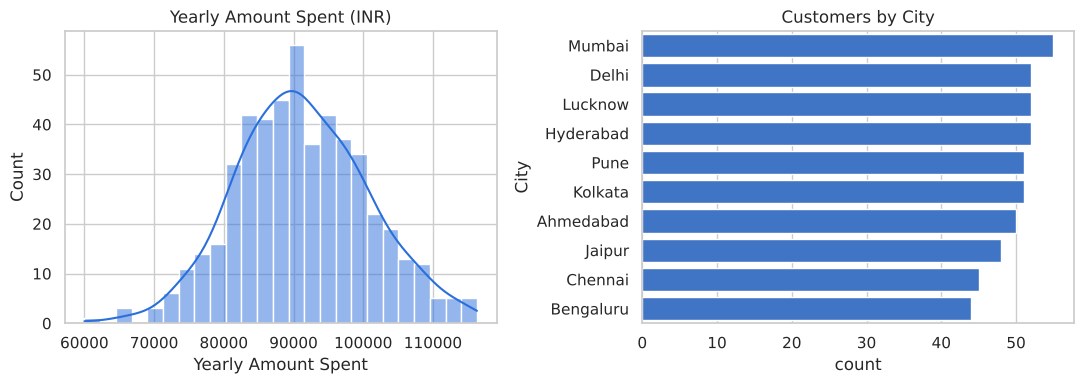

In [6]:
features = ["Avg. Orders per Month", "Time on App", "Time on Website", "Length of Membership"]
target = "Yearly Amount Spent"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[target], bins=25, kde=True, color=BLUE, ax=axes[0])
axes[0].set_title("Yearly Amount Spent (INR)")
sns.countplot(data=df, y="City", order=df["City"].value_counts().index, color=BLUE, ax=axes[1])
axes[1].set_title("Customers by City")
plt.tight_layout()
plt.show()

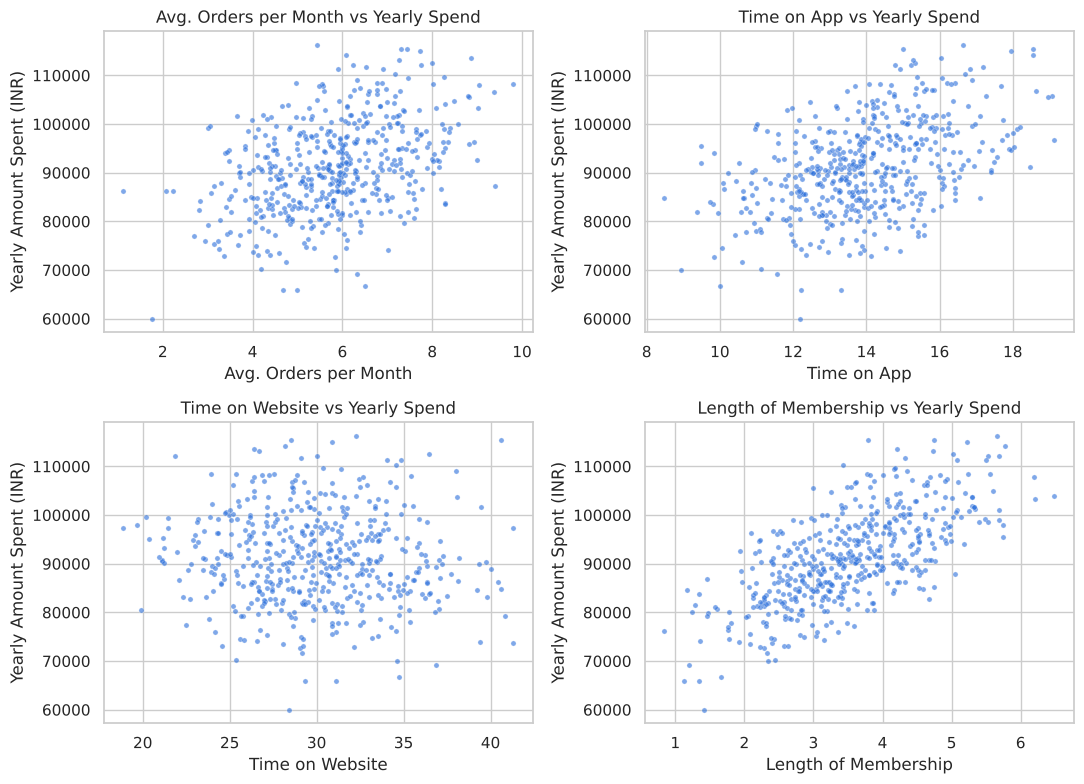

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), features):
    ax.scatter(df[feat], df[target], s=14, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.3)
    ax.set_xlabel(feat)
    ax.set_ylabel("Yearly Amount Spent (INR)")
    ax.set_title(f"{feat} vs Yearly Spend")
plt.tight_layout()
plt.show()

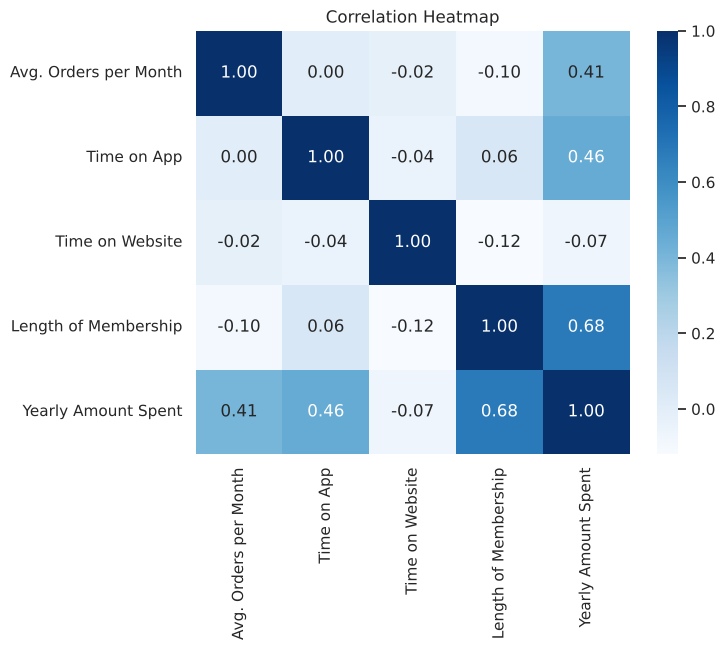

In [8]:
corr = df[features + [target]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Correlation Heatmap")
plt.show()

In [9]:
print("Correlation of each feature with Yearly Amount Spent:")
corr[target].drop(target).sort_values(ascending=False).round(3)

Correlation of each feature with Yearly Amount Spent:


Length of Membership     0.682
Time on App              0.456
Avg. Orders per Month    0.408
Time on Website         -0.068
Name: Yearly Amount Spent, dtype: float64

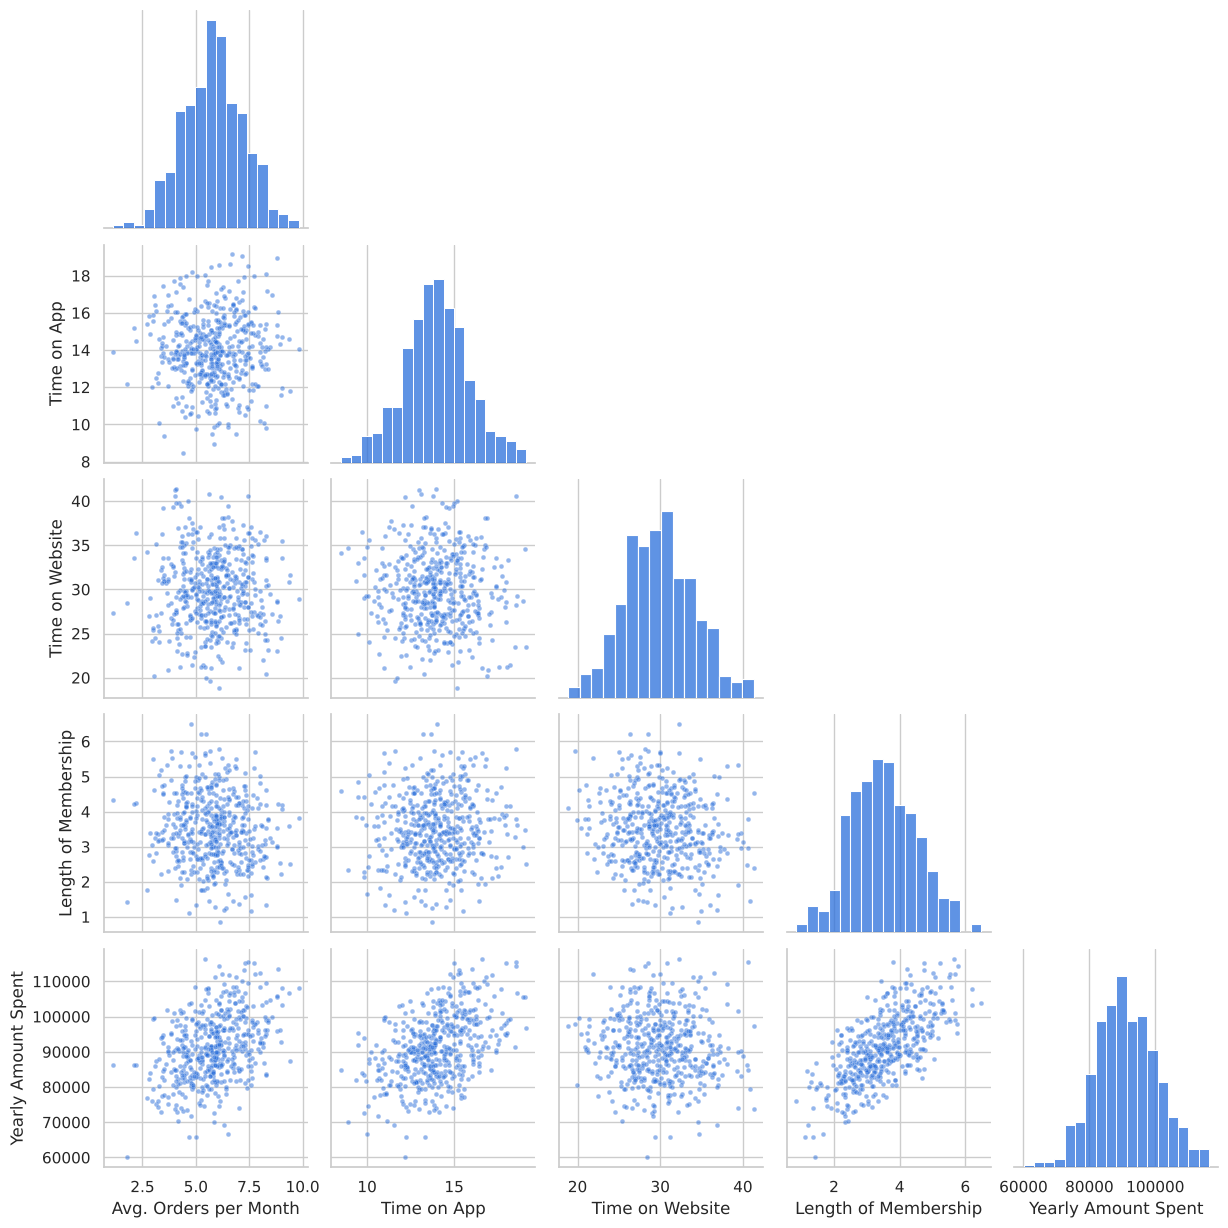

In [10]:
sns.pairplot(df[features + [target]], corner=True, plot_kws={"s": 12, "alpha": 0.5, "color": BLUE},
             diag_kws={"color": BLUE})
plt.show()

## 5. Select Features and Target

`Email`, `City` and `Avatar` are identifiers / categorical labels, so only the four numeric behaviour features are used.

In [11]:
X = df[features]
y = df[target]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500, 4)
y shape: (500,)


## 6. Train–Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 350
Testing samples : 150


## 7. Simple Linear Regression

Uses the single feature most correlated with spending: **Y = b0 + b1·X**

In [13]:
best_feature = corr[target].drop(target).abs().idxmax()
print("Feature with strongest correlation:", best_feature)

slr = LinearRegression()
slr.fit(X_train[[best_feature]], y_train)
print(f"Intercept (b0): {slr.intercept_:,.2f}")
print(f"Coefficient (b1): {slr.coef_[0]:,.2f}")
print(f"Equation: Spend = {slr.intercept_:,.0f} + {slr.coef_[0]:,.0f} x {best_feature}")

Feature with strongest correlation: Length of Membership
Intercept (b0): 68,221.55
Coefficient (b1): 6,683.75
Equation: Spend = 68,222 + 6,684 x Length of Membership


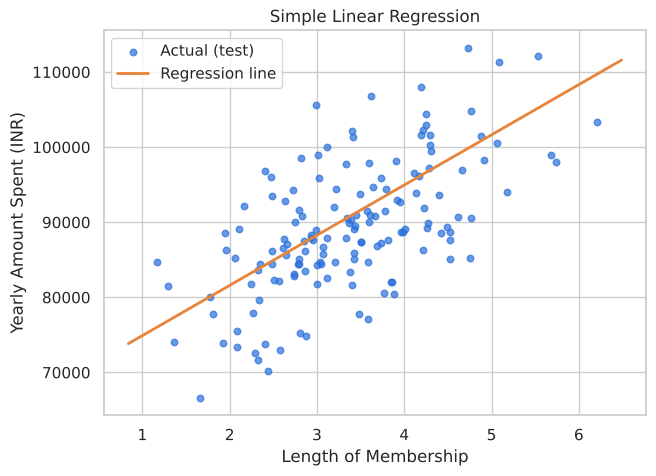

In [14]:
slr_pred = slr.predict(X_test[[best_feature]])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[best_feature], y_test, s=22, color=BLUE, alpha=0.7, label="Actual (test)")
xs = np.linspace(X[best_feature].min(), X[best_feature].max(), 100)
ax.plot(xs, slr.predict(pd.DataFrame({best_feature: xs})), color=ORANGE, linewidth=2, label="Regression line")
ax.set_xlabel(best_feature)
ax.set_ylabel("Yearly Amount Spent (INR)")
ax.set_title("Simple Linear Regression")
ax.legend()
plt.show()

## 8. Multiple Linear Regression

Uses all four features: **Y = b0 + b1·X1 + b2·X2 + b3·X3 + b4·X4**

In [15]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
print(f"Intercept (b0): {mlr.intercept_:,.2f}")
coef_df = pd.DataFrame({"Feature": features, "Coefficient": mlr.coef_.round(2)})
coef_df.sort_values("Coefficient", ascending=False).reset_index(drop=True)

Intercept (b0): 17,483.69


,Feature,Coefficient
0,Length of Membership,6785.29
1,Avg. Orders per Month,3196.99
2,Time on App,2088.37
3,Time on Website,79.03


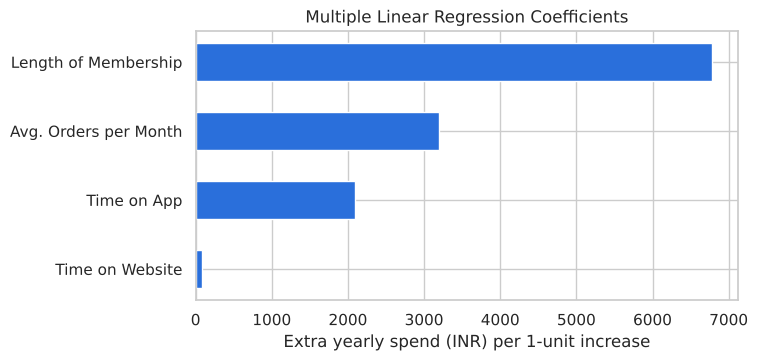

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.5))
order = coef_df.sort_values("Coefficient")
ax.barh(order["Feature"], order["Coefficient"], color=BLUE, height=0.55)
ax.set_xlabel("Extra yearly spend (INR) per 1-unit increase")
ax.set_title("Multiple Linear Regression Coefficients")
plt.show()

In [17]:
mlr_pred = mlr.predict(X_test)

## 9. Model Evaluation

In [18]:
def evaluate(name, y_true, y_hat):
    mae = mean_absolute_error(y_true, y_hat)
    mse = mean_squared_error(y_true, y_hat)
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_hat)}

metrics = pd.DataFrame([
    evaluate(f"Simple LR ({best_feature})", y_test, slr_pred),
    evaluate("Multiple LR (4 features)", y_test, mlr_pred),
]).set_index("Model")
metrics.round(4)

,MAE,MSE,RMSE,R2
Model,,,,
Simple LR (Length of Membership),5707.1344,5.030963e+07,7092.9278,0.3372
Multiple LR (4 features),3000.8142,1.415514e+07,3762.3316,0.8135


In [19]:
print("Interpretation:")
print(f"- Simple LR explains {metrics.iloc[0]['R2']:.1%} of the variance in yearly spend.")
print(f"- Multiple LR explains {metrics.iloc[1]['R2']:.1%} of the variance.")
print(f"- Multiple LR typical error (RMSE): Rs {metrics.iloc[1]['RMSE']:,.0f}")

Interpretation:
- Simple LR explains 33.7% of the variance in yearly spend.
- Multiple LR explains 81.4% of the variance.
- Multiple LR typical error (RMSE): Rs 3,762


## 10. Actual vs Predicted

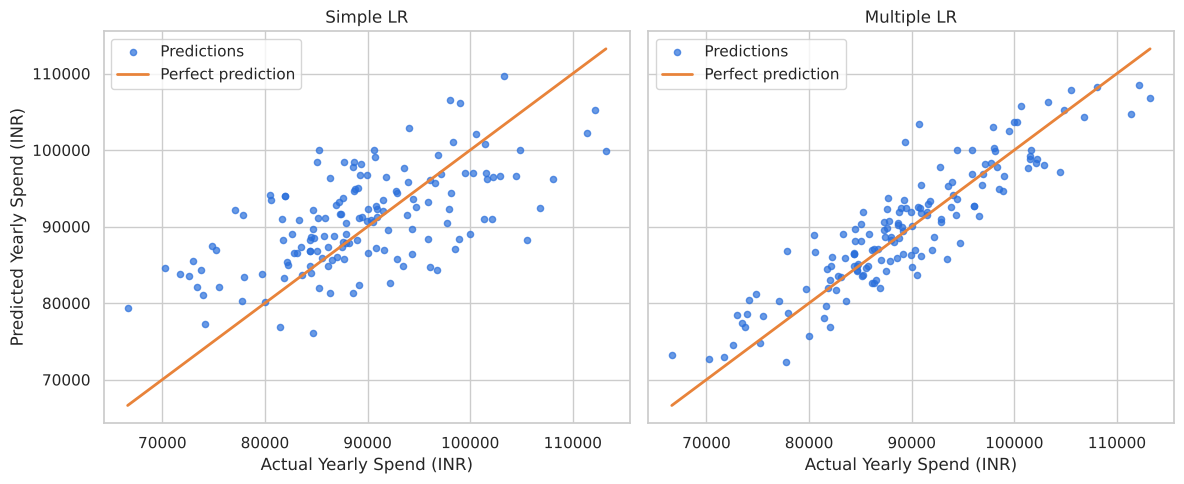

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lo, hi = y_test.min(), y_test.max()
for ax, pred, title in [(axes[0], slr_pred, "Simple LR"), (axes[1], mlr_pred, "Multiple LR")]:
    ax.scatter(y_test, pred, s=20, color=BLUE, alpha=0.7, label="Predictions")
    ax.plot([lo, hi], [lo, hi], color=ORANGE, linewidth=2, label="Perfect prediction")
    ax.set_xlabel("Actual Yearly Spend (INR)")
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel("Predicted Yearly Spend (INR)")
plt.tight_layout()
plt.show()

## 11. Residual Analysis (Multiple LR)

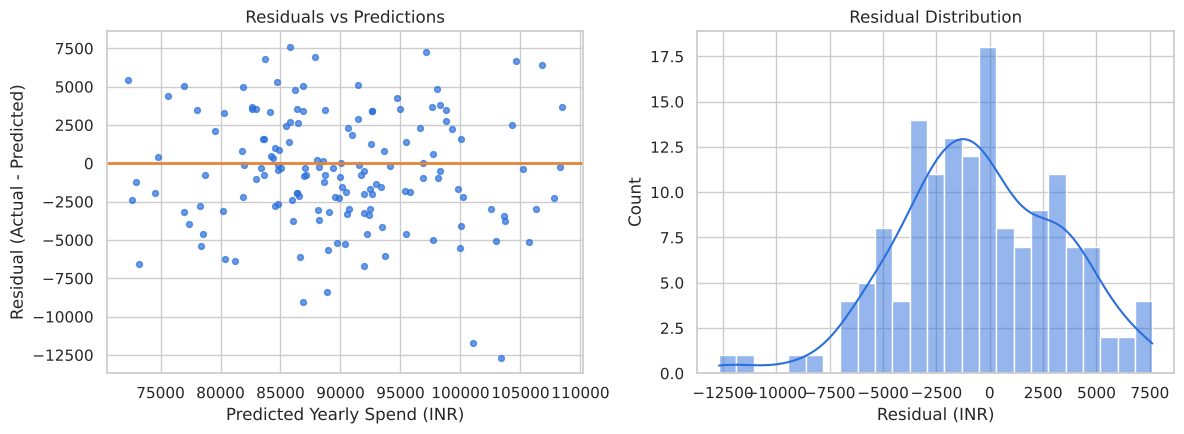

In [21]:
residuals = y_test - mlr_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(mlr_pred, residuals, s=18, color=BLUE, alpha=0.7)
axes[0].axhline(0, color=ORANGE, linewidth=2)
axes[0].set_xlabel("Predicted Yearly Spend (INR)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residuals vs Predictions")
sns.histplot(residuals, bins=25, kde=True, color=BLUE, ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual (INR)")
plt.tight_layout()
plt.show()

## 12. Predict Spending for New Customers

In [22]:
new_customers = pd.DataFrame({
    "Avg. Orders per Month": [4, 6, 9],
    "Time on App": [10.0, 14.0, 18.0],
    "Time on Website": [28.0, 30.0, 33.0],
    "Length of Membership": [1.0, 3.5, 5.5],
})
new_customers["Predicted Yearly Spend (INR)"] = mlr.predict(new_customers).round(0)
new_customers

,Avg. Orders per Month,Time on App,Time on Website,Length of Membership,Predicted Yearly Spend (INR)
0,4,10.0,28.0,1.0,60154.0
1,6,14.0,30.0,3.5,92022.0
2,9,18.0,33.0,5.5,123774.0


## 13. Save the Model

In [23]:
joblib.dump(mlr, "multiple_linear_regression_model.pkl")
loaded = joblib.load("multiple_linear_regression_model.pkl")
same = np.allclose(loaded.predict(X_test), mlr_pred)
print("Saved: multiple_linear_regression_model.pkl")
print("Reloaded model reproduces predictions:", same)

Saved: multiple_linear_regression_model.pkl
Reloaded model reproduces predictions: True


## 14. Conclusion

- Using all four features (Multiple LR) predicts yearly spend clearly better than one feature alone (Simple LR) – compare R² and RMSE in section 9.
- Length of membership, app time and order frequency have the biggest effect on spend; website time matters least.
- Residuals are centred around zero with no strong pattern, so a linear model is a good fit for this data.
- Possible next steps: Ridge/Lasso regression, feature selection, cross-validation, and a Streamlit app for predictions.